In [2]:
import sys
from pathlib import Path

raiz_projeto = str(Path().resolve().parent)
if raiz_projeto not in sys.path:
    sys.path.append(raiz_projeto)

import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.models import MLP
from src.train import treinar

os.makedirs("../reports/figures", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
sys.path.append(str(Path().resolve().parent))
from src.data_loader import preparar_dados_pytorch, fixar_sementes, SEEDS_TREINO

fixar_sementes(42)
loaders_reg, scaler_X_reg, scaler_y_reg, n_features_reg = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_regression.csv",
    target_col="term_gpa",
    tipo="reg",
    batch_size=32,
)

print(f"Features: {n_features_reg} | Treino: {len(loaders_reg['train'].dataset)} | "
      f"Val: {len(loaders_reg['val'].dataset)} | Teste: {len(loaders_reg['test'].dataset)}")

Features: 5 | Treino: 400 | Val: 100 | Teste: 126


In [5]:
# Configuração baseline de referência
cfg_base_reg = {
    "in_dim": n_features_reg,
    "out_dim": 1,
    "hidden": (32, 32),
    "activation": "ReLU",
    "dropout": 0.0,
}

resultados_reg = []
historicos_reg = {}

for seed in SEEDS_TREINO:
    fixar_sementes(seed)
    modelo_reg = MLP(**cfg_base_reg)
    loss_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(modelo_reg.parameters(), lr=1e-3)

    hist = treinar(
        modelo=modelo_reg,
        dl_tr=loaders_reg["train"],
        dl_val=loaders_reg["val"],
        loss_fn=loss_fn,
        otimizador=otimizador,
        n_epocas=200,
        paciencia=20,
        device=device,
    )
    historicos_reg[seed] = hist

    # Avaliação apenas na validação (revertendo a escala do target para pontos de GPA)
    modelo_reg.eval()
    preds_val, reais_val = [], []
    with torch.inference_mode():
        for xb, yb in loaders_reg["val"]:
            out = modelo_reg(xb.to(device)).cpu().numpy()
            preds_val.append(out)
            reais_val.append(yb.numpy())

    preds_val = scaler_y_reg.inverse_transform(np.vstack(preds_val)).ravel()
    reais_val = scaler_y_reg.inverse_transform(np.concatenate(reais_val).reshape(-1, 1)).ravel()
    
    rmse_val = float(np.sqrt(np.mean((preds_val - reais_val) ** 2)))
    mae_val = float(np.mean(np.abs(preds_val - reais_val)))
    resultados_reg.append({"seed": seed, "val_mse_scaled": min(hist["val"]), "val_rmse": rmse_val, "val_mae": mae_val})

rmses = [r["val_rmse"] for r in resultados_reg]
maes = [r["val_mae"] for r in resultados_reg]
print(f"Baseline Regressão ({len(SEEDS_TREINO)} sementes) -> "
      f"RMSE Val: {np.mean(rmses):.4f} ± {np.std(rmses):.4f} | "
      f"MAE Val: {np.mean(maes):.4f} ± {np.std(maes):.4f}")

/home/henderson/Documentos/MPL-com-pytorch/.venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/henderson/Documentos/MPL-com-pytorch/.venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([16])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/home/henderson/Documentos/MPL-com-pytorch/.venv/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([4])) that is different to the input size (torch.Size([4, 1])). This will likely 

Baseline Regressão (5 sementes) -> RMSE Val: 0.6048 ± 0.0043 | MAE Val: 0.4121 ± 0.0037


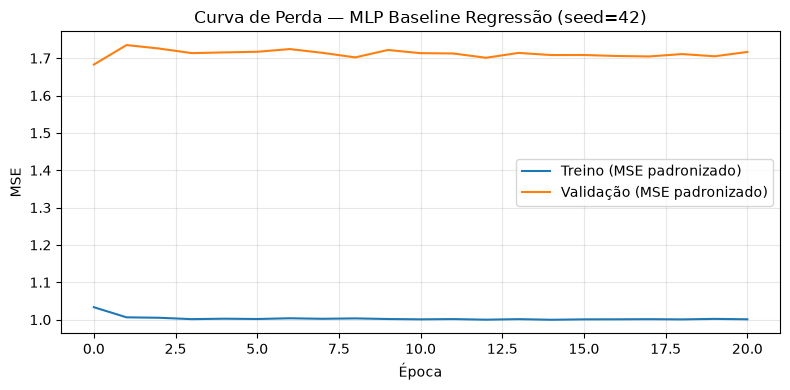

In [6]:
# Gráfico das curvas de perda (Treino vs. Validação) da primeira semente
seed_ref = SEEDS_TREINO[0]
plt.figure(figsize=(8, 4))
plt.plot(historicos_reg[seed_ref]["treino"], label="Treino (MSE padronizado)")
plt.plot(historicos_reg[seed_ref]["val"], label="Validação (MSE padronizado)")
plt.title(f"Curva de Perda — MLP Baseline Regressão (seed={seed_ref})")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/curva_perda_baseline_reg.png", dpi=150)
plt.show()